# Matplotlib & Seaborn Complete Revision — Lectures 59–66
Beginner-friendly revision notebook: chart concepts, graph features, examples, practice and company-style questions.

Run cells from top to bottom. If required, install libraries in a separate cell with:
`%pip install pandas numpy matplotlib seaborn`

## Contents
1. Setup and chart selection
2. Line charts
3. Bar charts
4. Pie charts
5. Histograms
6. Scatter plots
7. Box plots and outliers
8. Correlation heatmaps
9. Subplots and pair plots
10. Mini-project
11. Cheat sheet and challenging interview questions

## 1. Setup and chart selection

| Need | Chart | Function |
|---|---|---|
| Trend over time | Line | `plt.plot()` |
| Compare categories | Bar | `plt.bar()` / `plt.barh()` |
| Parts of a whole | Pie (few categories) | `plt.pie()` |
| Numerical distribution | Histogram | `plt.hist()` |
| Relationship between two numeric columns | Scatter | `plt.scatter()` |
| Quartiles and potential outliers | Box plot | `plt.boxplot()` |
| Correlation overview | Heatmap | `sns.heatmap()` |
| Multiple charts in one figure | Subplots | `plt.subplots()` |
| Pairwise variable exploration | Pair plot | `sns.pairplot()` |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

Pandas: 3.0.6
NumPy: 2.4.6
Matplotlib: 3.11.2
Seaborn: 0.13.2


## Lecture 59 — Line charts
Use line charts for ordered data such as monthly sales, daily visits, or temperature over time.

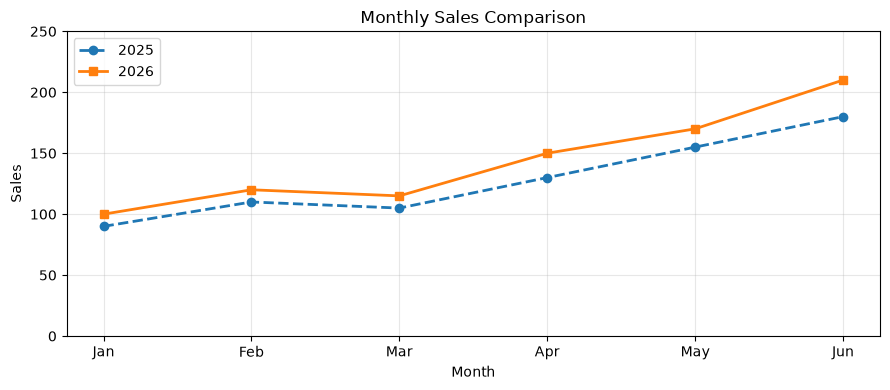

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales_2025 = [90, 110, 105, 130, 155, 180]
sales_2026 = [100, 120, 115, 150, 170, 210]

plt.figure(figsize=(9, 4))
plt.plot(months, sales_2025, marker="o", linestyle="--", linewidth=2, label="2025")
plt.plot(months, sales_2026, marker="s", linestyle="-", linewidth=2, label="2026")
plt.title("Monthly Sales Comparison")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.legend()
plt.ylim(0, 250)
plt.tight_layout()
# Save when needed: plt.savefig("sales.png", dpi=300, bbox_inches="tight")
plt.show()

**Features:** `figsize`, `marker`, `linestyle`, `linewidth`, `markersize`, `label`, `legend()`, `grid()`, `xlim()`, `ylim()`, `xticks()`, `yticks()`, `savefig()`. Use lines when the x-axis has a meaningful order.

## Lecture 60 — Bar charts and comparisons
Use bars to compare categories. `bar()` makes vertical bars; `barh()` makes horizontal bars.

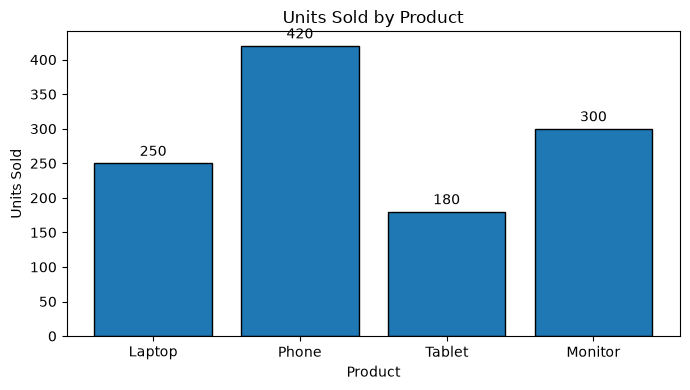

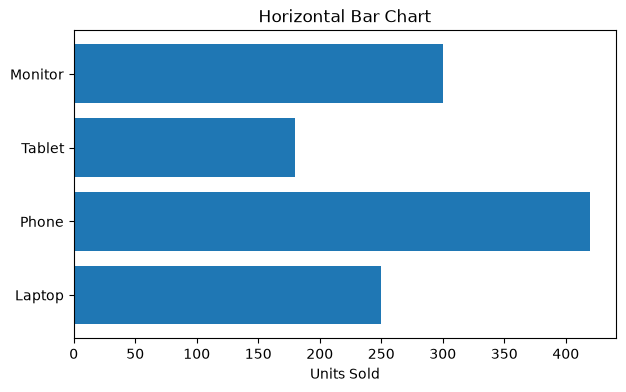

In [3]:
products = ["Laptop", "Phone", "Tablet", "Monitor"]
units = [250, 420, 180, 300]

plt.figure(figsize=(7, 4))
bars = plt.bar(products, units, edgecolor="black")
plt.bar_label(bars, padding=3)
plt.title("Units Sold by Product")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.barh(products, units)
plt.title("Horizontal Bar Chart")
plt.xlabel("Units Sold")
plt.show()

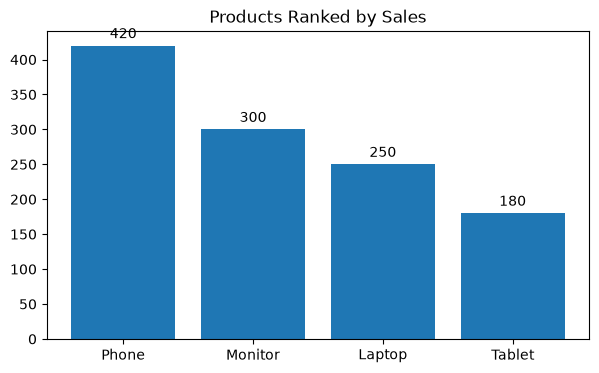

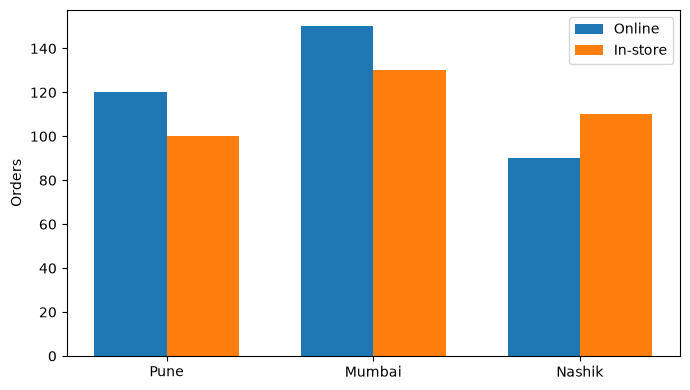

In [4]:
# Sort bars from highest to lowest
pairs = sorted(zip(products, units), key=lambda x: x[1], reverse=True)
p_sorted = [x[0] for x in pairs]
v_sorted = [x[1] for x in pairs]

plt.figure(figsize=(7, 4))
bars = plt.bar(p_sorted, v_sorted)
plt.bar_label(bars, padding=3)
plt.title("Products Ranked by Sales")
plt.show()

# Grouped bars
cities = ["Pune", "Mumbai", "Nashik"]
online = [120, 150, 90]
store = [100, 130, 110]
x = np.arange(len(cities))
w = 0.35
plt.figure(figsize=(7, 4))
plt.bar(x-w/2, online, w, label="Online")
plt.bar(x+w/2, store, w, label="In-store")
plt.xticks(x, cities)
plt.ylabel("Orders")
plt.legend()
plt.tight_layout()
plt.show()

**Features:** `width`, `color`, `edgecolor`, `alpha`, `bar_label()`, `barh()`, sorting, grouped bars, grid. Bar charts compare categories; histograms show numerical distributions.

## Lecture 61 — Pie charts and percentages
Use pie charts for a small number of non-negative categories making up a whole. Bar charts are often clearer for precise comparisons.

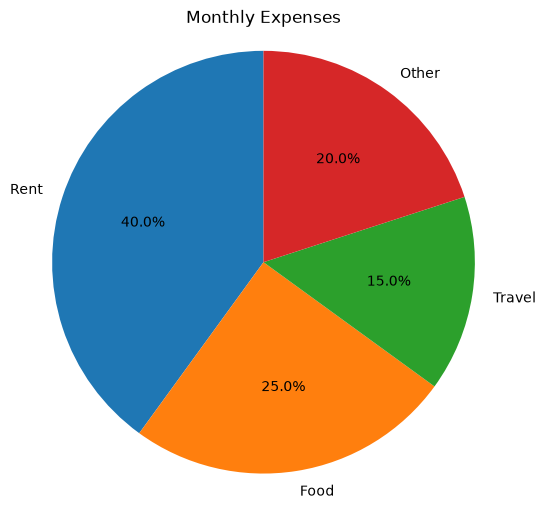

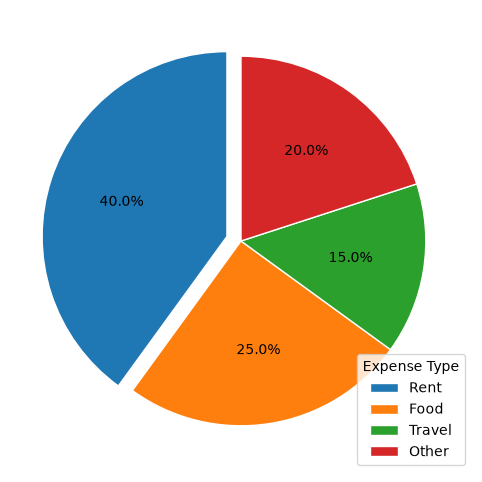

  Expense_Type  Expense  Percentage
0         Rent    40000        40.0
1         Food    25000        25.0
2       Travel    15000        15.0
3        Other    20000        20.0


In [5]:
expense_types = ["Rent", "Food", "Travel", "Other"]
expenses = [40000, 25000, 15000, 20000]

plt.figure(figsize=(6, 6))
plt.pie(expenses, labels=expense_types, autopct="%1.1f%%", startangle=90)
plt.title("Monthly Expenses")
plt.axis("equal")
plt.show()

# Explode a slice and use a legend
plt.figure(figsize=(7, 6))
plt.pie(expenses, autopct="%1.1f%%", startangle=90,
        explode=[0.08, 0, 0, 0], wedgeprops={"edgecolor": "white"})
plt.legend(expense_types, title="Expense Type")
plt.show()

expense_df = pd.DataFrame({"Expense_Type": expense_types, "Expense": expenses})
expense_df["Percentage"] = expense_df["Expense"] / expense_df["Expense"].sum() * 100
print(expense_df)

**Features:** `labels`, `autopct`, `startangle`, `explode`, `wedgeprops`, `legend`, `axis("equal")`. Avoid too many slices and negative values.

## Lecture 62 — Histograms and distributions
A histogram groups numerical values into bins and shows the frequency in each interval.

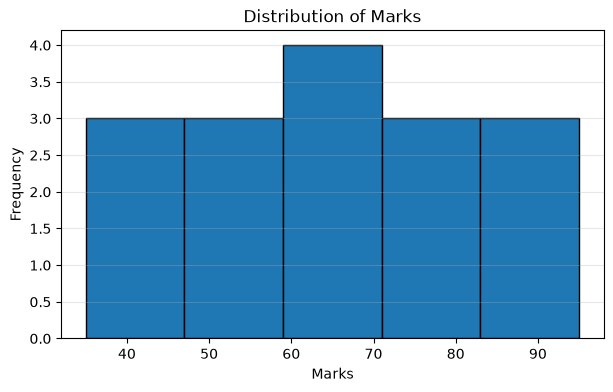

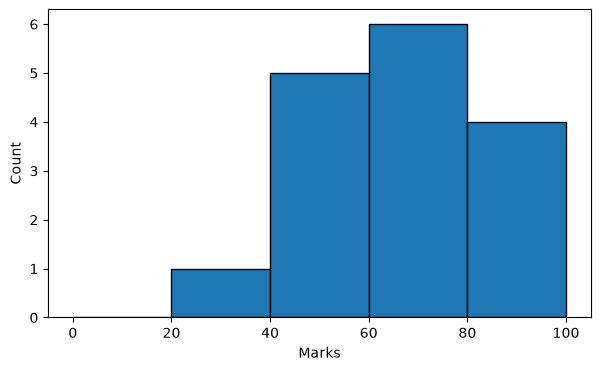

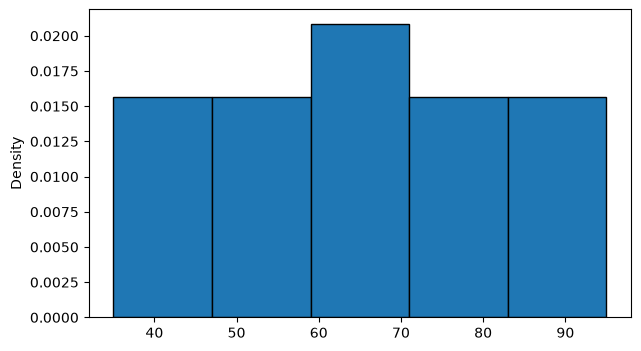

In [6]:
marks = [35, 40, 42, 48, 50, 55, 60, 62, 65, 70, 72, 75, 80, 85, 90, 95]

plt.figure(figsize=(7, 4))
plt.hist(marks, bins=5, edgecolor="black")
plt.title("Distribution of Marks")
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Explicit bin boundaries
plt.figure(figsize=(7, 4))
plt.hist(marks, bins=[0, 20, 40, 60, 80, 100], edgecolor="black")
plt.xlabel("Marks")
plt.ylabel("Count")
plt.show()

# density=True makes total area equal to 1
plt.figure(figsize=(7, 4))
plt.hist(marks, bins=5, density=True, edgecolor="black")
plt.ylabel("Density")
plt.show()

**Interpretation:** Look for concentration, spread, skewness, multiple peaks, and unusual observations. `bins` changes the view of the distribution; try different reasonable values.

## Lecture 63 — Scatter plots and relationships
Use scatter plots to compare two numerical variables; each point represents one observation.

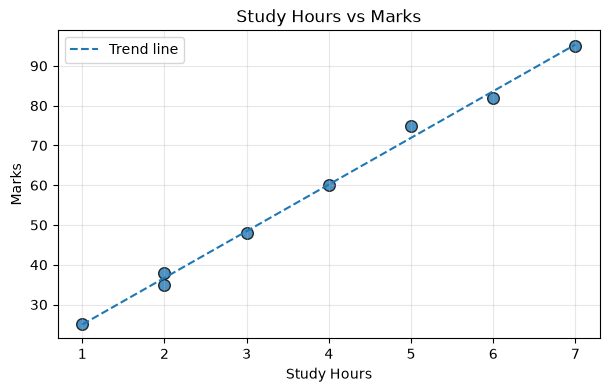

Correlation: 0.9980209822008596
             Study_Hours     Marks
Study_Hours     1.000000  0.998021
Marks           0.998021  1.000000


In [7]:
study_hours = np.array([1, 2, 2, 3, 4, 5, 6, 7])
student_marks = np.array([25, 35, 38, 48, 60, 75, 82, 95])

plt.figure(figsize=(7, 4))
plt.scatter(study_hours, student_marks, s=70, alpha=0.8, edgecolor="black")
slope, intercept = np.polyfit(study_hours, student_marks, 1)
plt.plot(study_hours, slope*study_hours + intercept, "--", label="Trend line")
plt.title("Study Hours vs Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

rel = pd.DataFrame({"Study_Hours": study_hours, "Marks": student_marks})
print("Correlation:", rel["Study_Hours"].corr(rel["Marks"]))
print(rel.corr(numeric_only=True))

**Features:** `s`, `alpha`, `color`, `marker`, `edgecolor`, `label`, `legend`, optional trend line. Correlation and a trend do not prove causation; near-zero correlation can miss nonlinear relationships.

## Lecture 64 — Box plots and outlier detection
- Q1: 25th percentile; median/Q2: 50th percentile; Q3: 75th percentile.
- IQR = Q3 − Q1.
- Lower fence = Q1 − 1.5 × IQR.
- Upper fence = Q3 + 1.5 × IQR.
- Whiskers generally reach the most extreme observations within the fences, not necessarily actual minimum and maximum.

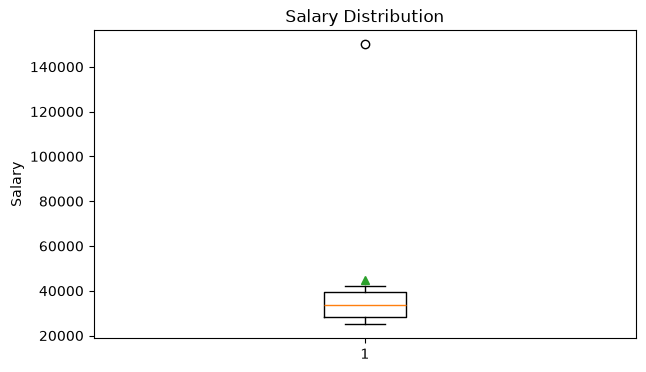

Q1: 28500.0 Q3: 39250.0 IQR: 10750.0
Lower/upper fences: 12375.0 55375.0
Potential outliers: [150000]


In [8]:
salaries = [25000, 27000, 28000, 30000, 32000, 35000, 37000, 40000, 42000, 150000]

plt.figure(figsize=(7, 4))
plt.boxplot(salaries, showmeans=True)
plt.title("Salary Distribution")
plt.ylabel("Salary")
plt.show()

s = pd.Series(salaries)
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = s[(s < lower) | (s > upper)]
print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Lower/upper fences:", lower, upper)
print("Potential outliers:", outliers.tolist())

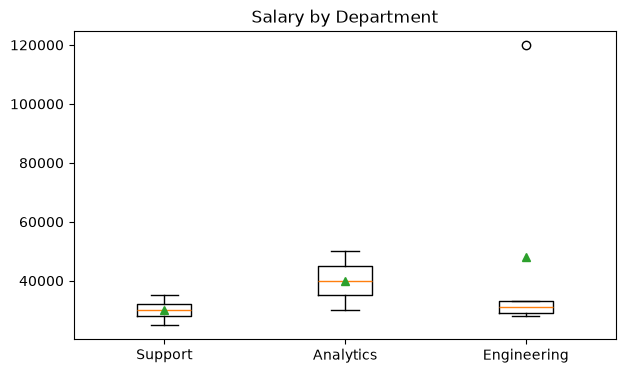

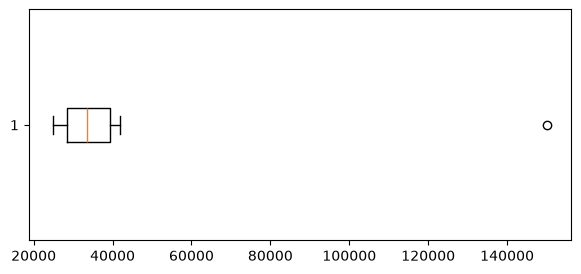

In [9]:
departments = [
    [25000, 28000, 30000, 32000, 35000],
    [30000, 35000, 40000, 45000, 50000],
    [28000, 29000, 31000, 33000, 120000]
]
plt.figure(figsize=(7, 4))
plt.boxplot(departments, tick_labels=["Support", "Analytics", "Engineering"], showmeans=True)
plt.title("Salary by Department")
plt.show()

# Horizontal box plot on recent Matplotlib versions
plt.figure(figsize=(7, 3))
plt.boxplot(salaries, orientation="horizontal")
plt.show()

**Important:** An outlier is not automatically an error. Check its source and context before removing it. Older Matplotlib versions may use `labels=` instead of `tick_labels=`, and `vert=False` instead of `orientation="horizontal"`.

## Lecture 65 — Correlation matrix and heatmap
Correlation ranges from -1 to +1. Positive = variables tend to move together; negative = one tends to decrease as the other increases; near zero = little linear association.

                  Study_Hours  Attendance  Assignment_Score  Marks
Study_Hours              1.00        0.99              0.99   0.99
Attendance               0.99        1.00              1.00   1.00
Assignment_Score         0.99        1.00              1.00   1.00
Marks                    0.99        1.00              1.00   1.00


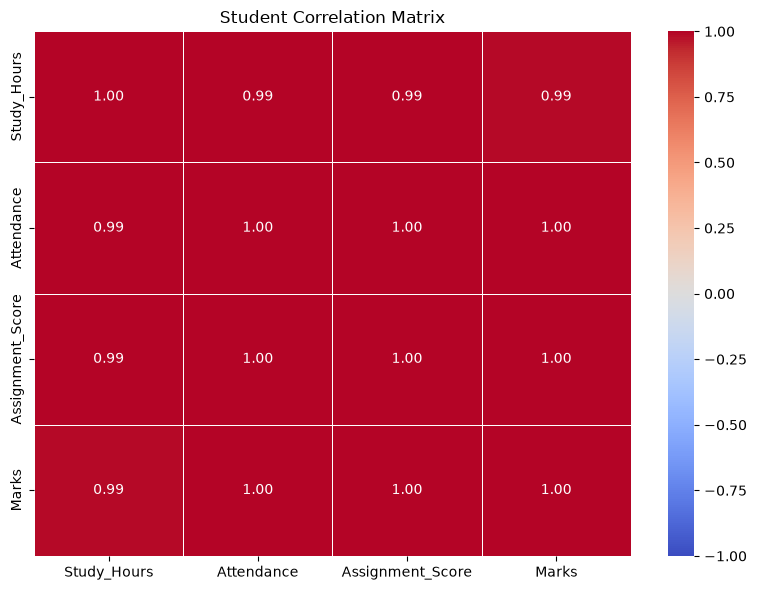

In [10]:
student_df = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6],
    "Attendance": [50, 55, 65, 70, 80, 90],
    "Assignment_Score": [40, 45, 60, 65, 75, 85],
    "Marks": [35, 40, 55, 60, 75, 88]
})
corr = student_df.corr(numeric_only=True)
print(corr.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
            fmt=".2f", linewidths=0.5, cbar=True)
plt.title("Student Correlation Matrix")
plt.tight_layout()
plt.show()

**Heatmap features:** `annot`, `cmap`, `vmin`, `vmax`, `fmt`, `linewidths`, `cbar`, `figsize`. The diagonal is 1 and the matrix is symmetric. Correlation does not prove causation and may miss nonlinear relationships.

## Lecture 66 — Subplots and pair plots
`plt.subplots(rows, columns)` creates multiple charts in one figure. Use `ax[0]` for a one-row set of axes, and `ax[row, column]` for a 2-D grid.

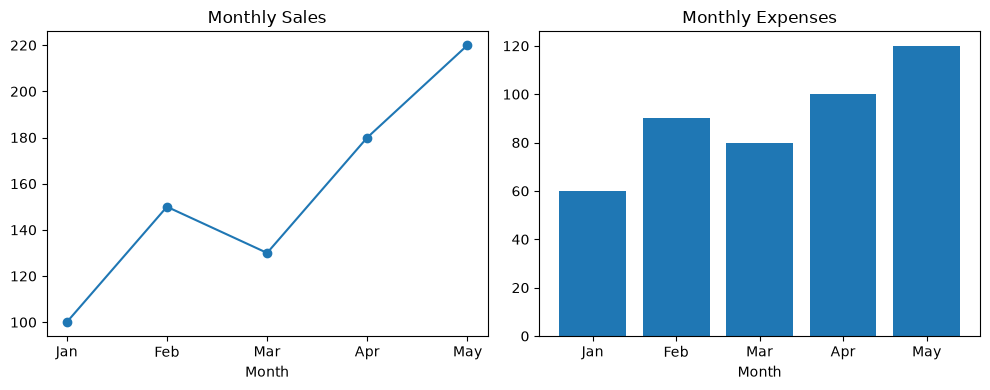

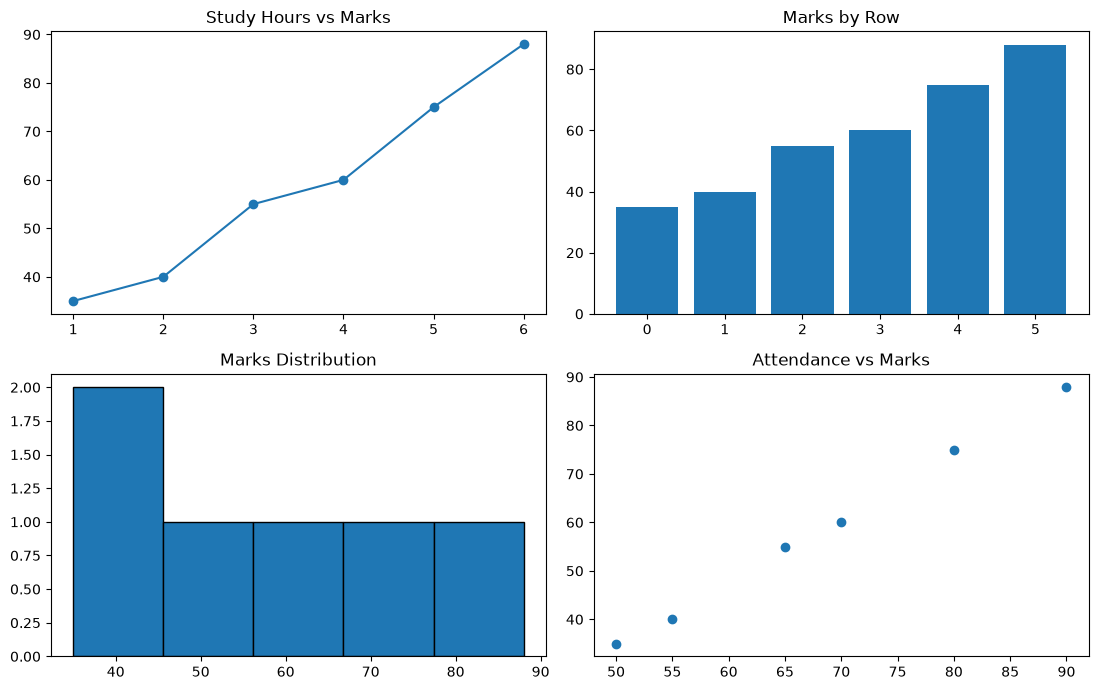

In [11]:
months = ["Jan", "Feb", "Mar", "Apr", "May"]
monthly_sales = [100, 150, 130, 180, 220]
monthly_expenses = [60, 90, 80, 100, 120]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(months, monthly_sales, marker="o")
ax[0].set_title("Monthly Sales")
ax[0].set_xlabel("Month")
ax[1].bar(months, monthly_expenses)
ax[1].set_title("Monthly Expenses")
ax[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].plot(student_df["Study_Hours"], student_df["Marks"], marker="o")
ax[0, 0].set_title("Study Hours vs Marks")
ax[0, 1].bar(range(len(student_df)), student_df["Marks"])
ax[0, 1].set_title("Marks by Row")
ax[1, 0].hist(student_df["Marks"], bins=5, edgecolor="black")
ax[1, 0].set_title("Marks Distribution")
ax[1, 1].scatter(student_df["Attendance"], student_df["Marks"])
ax[1, 1].set_title("Attendance vs Marks")
plt.tight_layout()
plt.show()

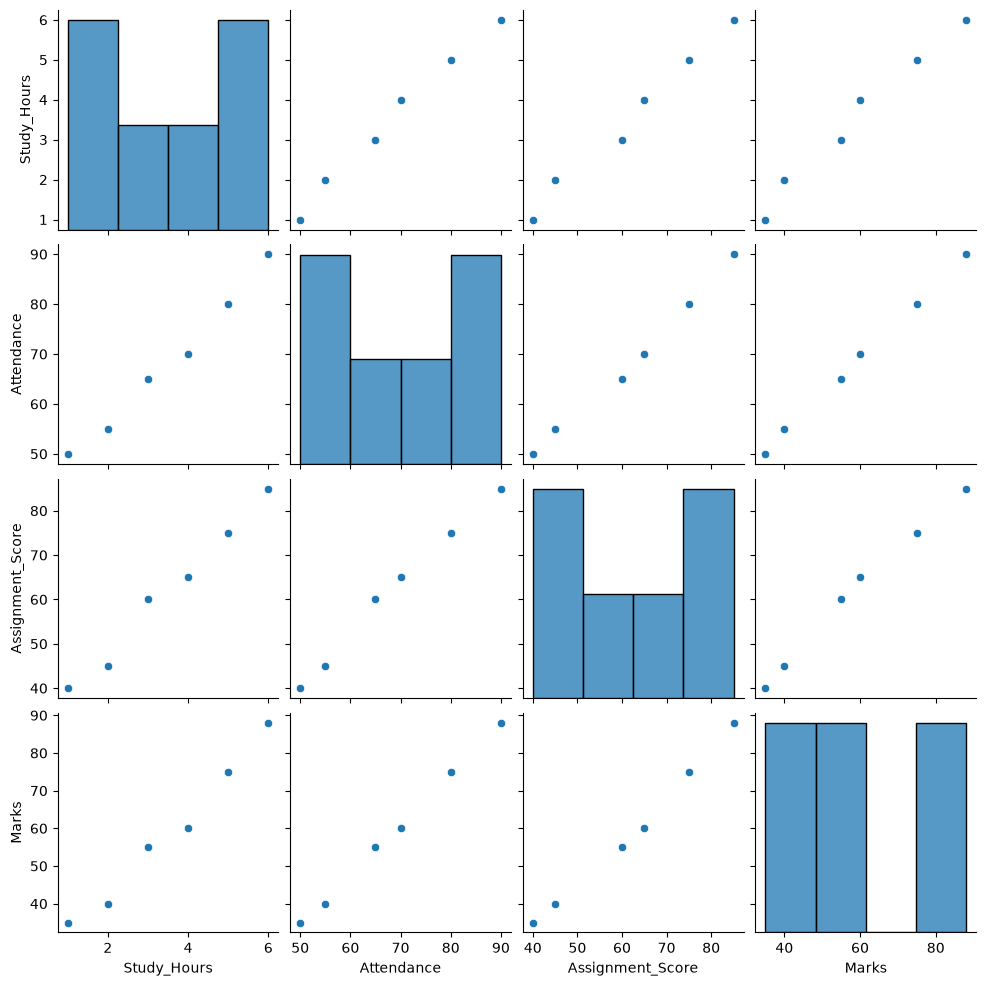

In [12]:
# Pair plot: pairwise relationships and diagonal distributions
sns.pairplot(student_df)
plt.show()

# With a categorical grouping column, you can use:
# sns.pairplot(df, hue="Result")
# Too many columns can make pair plots crowded.

## Mini-project — Student Performance EDA
Questions: Which student has the highest marks? What does the distribution look like? Are study hours positively associated with marks? Why doesn't this prove causation?

,Student,Study_Hours,Attendance,Assignment_Score,Marks
0,A,1,45,30,25
1,B,2,50,40,35
2,C,2,55,42,38
3,D,3,60,50,48
4,E,4,70,65,60


,Study_Hours,Attendance,Assignment_Score,Marks
count,8.00000,8.000000,8.000000,8.000000
mean,3.75000,67.500000,59.500000,57.250000
std,2.12132,17.928429,22.488092,24.932767
min,1.00000,45.000000,30.000000,25.000000
25%,2.00000,53.750000,41.500000,37.250000
50%,3.50000,65.000000,57.500000,54.000000
75%,5.25000,81.250000,75.250000,76.750000
max,7.00000,95.000000,92.000000,95.000000


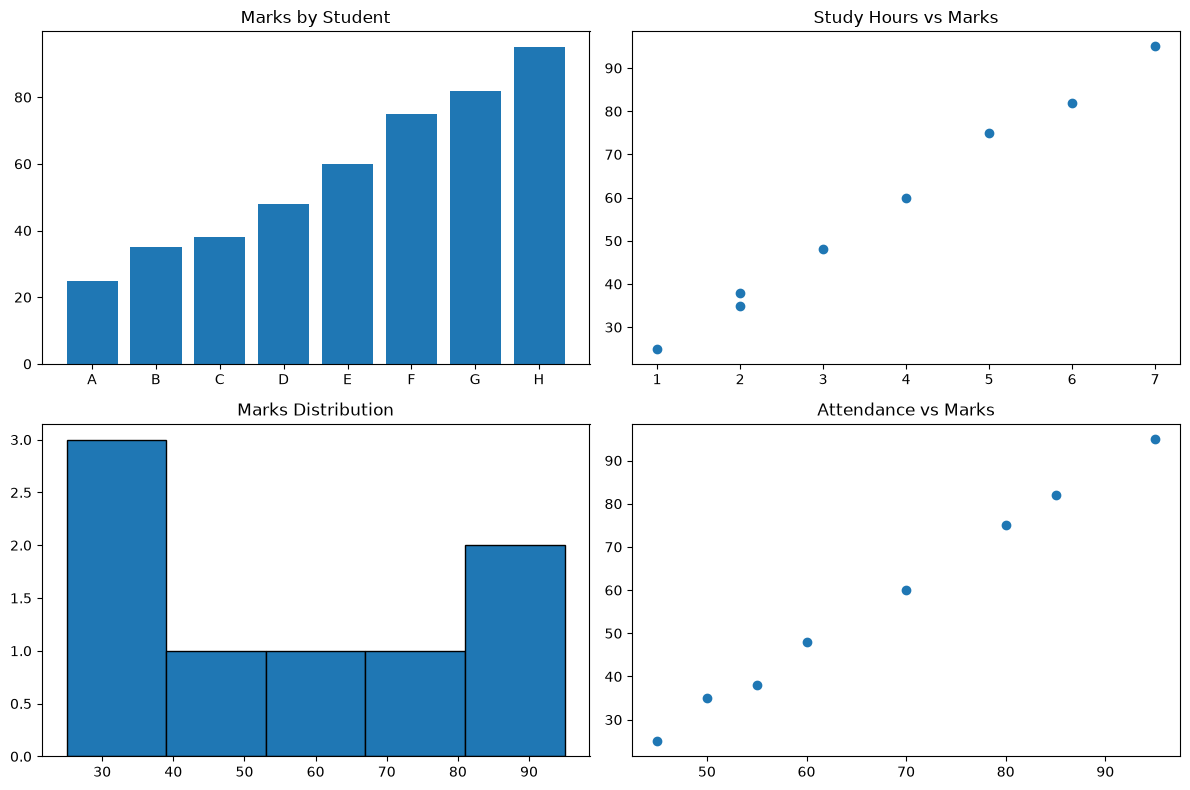

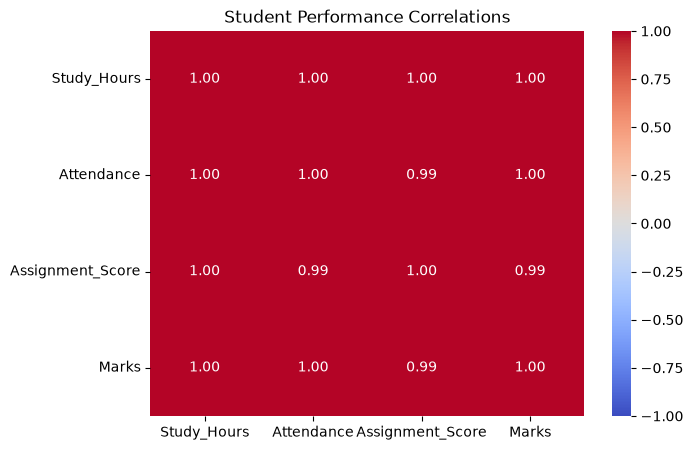

In [13]:
project_df = pd.DataFrame({
    "Student": list("ABCDEFGH"),
    "Study_Hours": [1, 2, 2, 3, 4, 5, 6, 7],
    "Attendance": [45, 50, 55, 60, 70, 80, 85, 95],
    "Assignment_Score": [30, 40, 42, 50, 65, 72, 85, 92],
    "Marks": [25, 35, 38, 48, 60, 75, 82, 95]
})
display(project_df.head())
display(project_df.describe())

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].bar(project_df["Student"], project_df["Marks"])
ax[0, 0].set_title("Marks by Student")
ax[0, 1].scatter(project_df["Study_Hours"], project_df["Marks"])
ax[0, 1].set_title("Study Hours vs Marks")
ax[1, 0].hist(project_df["Marks"], bins=5, edgecolor="black")
ax[1, 0].set_title("Marks Distribution")
ax[1, 1].scatter(project_df["Attendance"], project_df["Marks"])
ax[1, 1].set_title("Attendance vs Marks")
plt.tight_layout()
plt.show()

corr = project_df.select_dtypes(include="number").corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Student Performance Correlations")
plt.show()

## Plot feature cheat sheet

| Feature | Syntax | Purpose |
|---|---|---|
| Figure size | `plt.figure(figsize=(8,4))` | Set dimensions |
| Subplots | `fig, ax = plt.subplots(2,2)` | Multiple axes |
| Title | `plt.title()` / `ax.set_title()` | Chart title |
| Labels | `plt.xlabel()`, `plt.ylabel()` | Explain axes |
| Legend | `plt.legend()` | Identify series |
| Grid | `plt.grid(True, alpha=.3)` | Help compare values |
| Limits | `plt.xlim()`, `plt.ylim()` | Visible range |
| Ticks | `plt.xticks()`, `plt.yticks()` | Tick positions/labels |
| Layout | `plt.tight_layout()` | Reduce overlap |
| Save | `plt.savefig("chart.png", dpi=300, bbox_inches="tight")` | Export image |
| Transparency | `alpha=0.5` | Opacity |
| Bar labels | `plt.bar_label(bars)` | Values on bars |
| Histogram bins | `plt.hist(x, bins=10)` | Intervals |
| Heatmap annotations | `sns.heatmap(corr, annot=True)` | Values in cells |
| Pair plot groups | `sns.pairplot(df, hue="Group")` | Color by category |

## Practice questions — try before checking answers
1. Which chart compares five product sales categories?
2. Which chart examines customer-age distribution?
3. What does `marker="o"` do?
4. What does `plt.tight_layout()` help with?
5. What does `bins=10` mean?
6. Explain bar chart vs histogram.
7. What does correlation -0.85 suggest?
8. Why investigate outliers before removing them?
9. What does `annot=True` do in a heatmap?
10. What does `hue` do in `sns.pairplot()`?

### Answers
1. Bar chart.
2. Histogram.
3. Adds circular markers at data points.
4. Reduces overlap between chart elements.
5. Divides the range into ten bins.
6. Bars compare categories; histograms show numeric distributions in intervals.
7. Strong negative linear association.
8. The point may be valid, erroneous, or a rare important case.
9. Displays values inside heatmap cells.
10. Colors observations by a categorical variable.

## Challenging company-style questions

These are realistic interview-practice scenarios, not claims about official questions from a specific company.

**Q1. Sales trend:** Compare two years of monthly sales. Which chart and features would you use?

**Q2. Product ranking:** A DataFrame has `Product` and `Revenue`. Sort descending, create a bar chart, and show values above bars.

**Q3. Customer ages:** Which chart shows age distribution, and which parameter changes the intervals?

**Q4. Causation:** Advertising spending and sales rise together in a scatter plot. Does this prove advertising caused the increase?

**Q5. Salary outlier:** A box plot shows one very high salary. What do you check before removing it?

**Q6. 25-column heatmap:** How do you create it and what readability issue can occur?

**Q7. Customer segments:** How do you compare order-value distributions for three segments?

**Q8. EDA report:** How would you show revenue trend, product comparison, and revenue distribution in one figure?

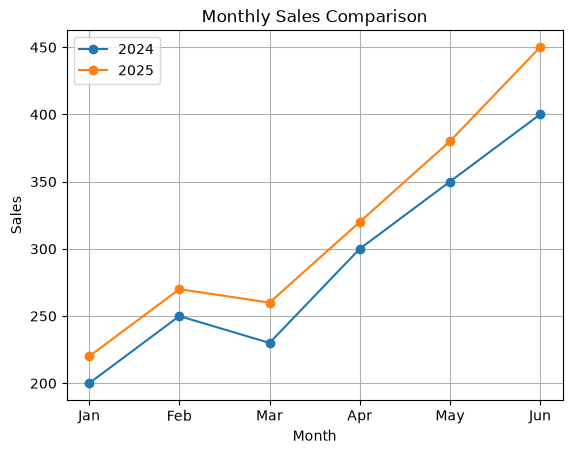

In [14]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]

sales_2024 = [200, 250, 230, 300, 350, 400]
sales_2025 = [220, 270, 260, 320, 380, 450]

plt.plot(months, sales_2024, marker="o", label="2024")
plt.plot(months, sales_2025, marker="o", label="2025")

plt.title("Monthly Sales Comparison")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

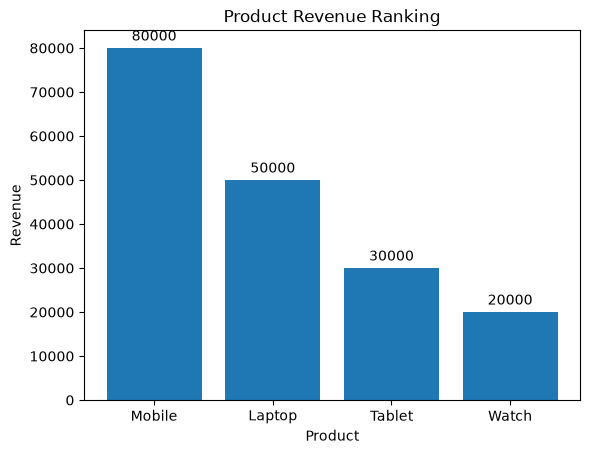

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Product": ["Laptop", "Mobile", "Tablet", "Watch"],
    "Revenue": [50000, 80000, 30000, 20000]
})

df = df.sort_values("Revenue", ascending=False)

bars = plt.bar(df["Product"], df["Revenue"])

plt.bar_label(bars, padding=3)
plt.title("Product Revenue Ranking")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.show()

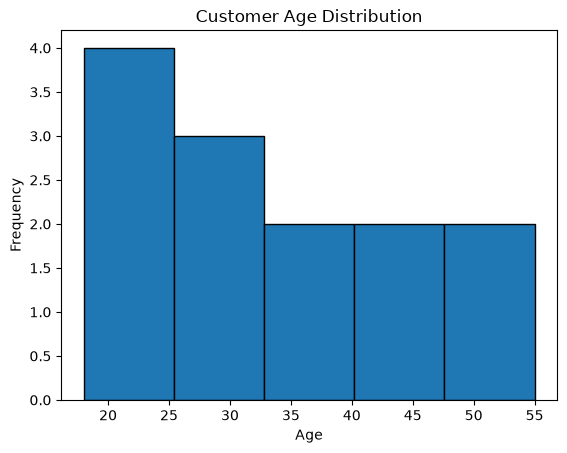

In [16]:
ages = [18, 22, 25, 25, 28, 30, 32, 35, 40, 42, 45, 50, 55]

plt.hist(ages, bins=5, edgecolor="black")

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

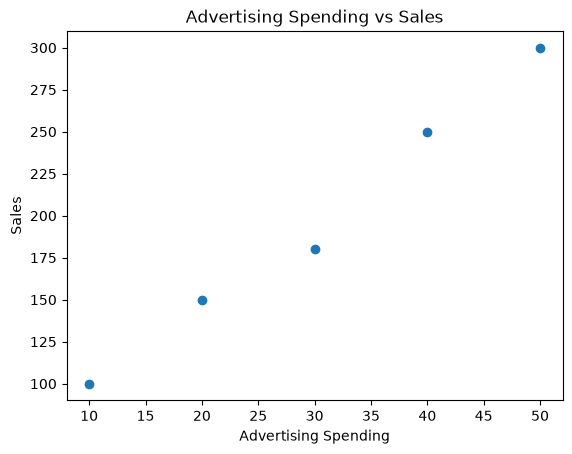

In [17]:
advertising = [10, 20, 30, 40, 50]
sales = [100, 150, 180, 250, 300]

plt.scatter(advertising, sales)
plt.title("Advertising Spending vs Sales")
plt.xlabel("Advertising Spending")
plt.ylabel("Sales")
plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x1a8f38f0110>,
 'caps': [<matplotlib.lines.Line2D at 0x1a8f38f1c10>,
 'boxes': [<matplotlib.lines.Line2D at 0x1a8f38eb690>],
 'medians': [<matplotlib.lines.Line2D at 0x1a8f38f3590>],
 'fliers': [<matplotlib.lines.Line2D at 0x1a8f38f8310>],
 'means': []}

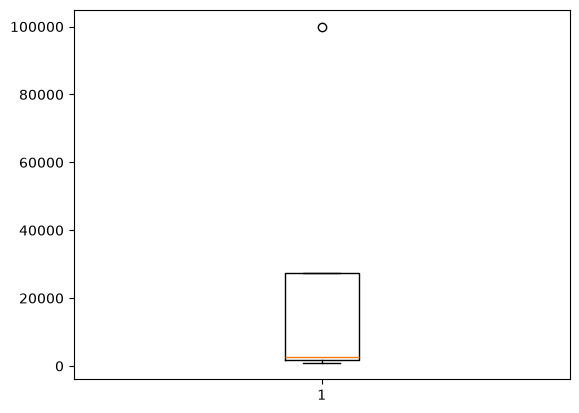

In [18]:
salary = [1000,2000,3000,100000]
plt.boxplot(salary)

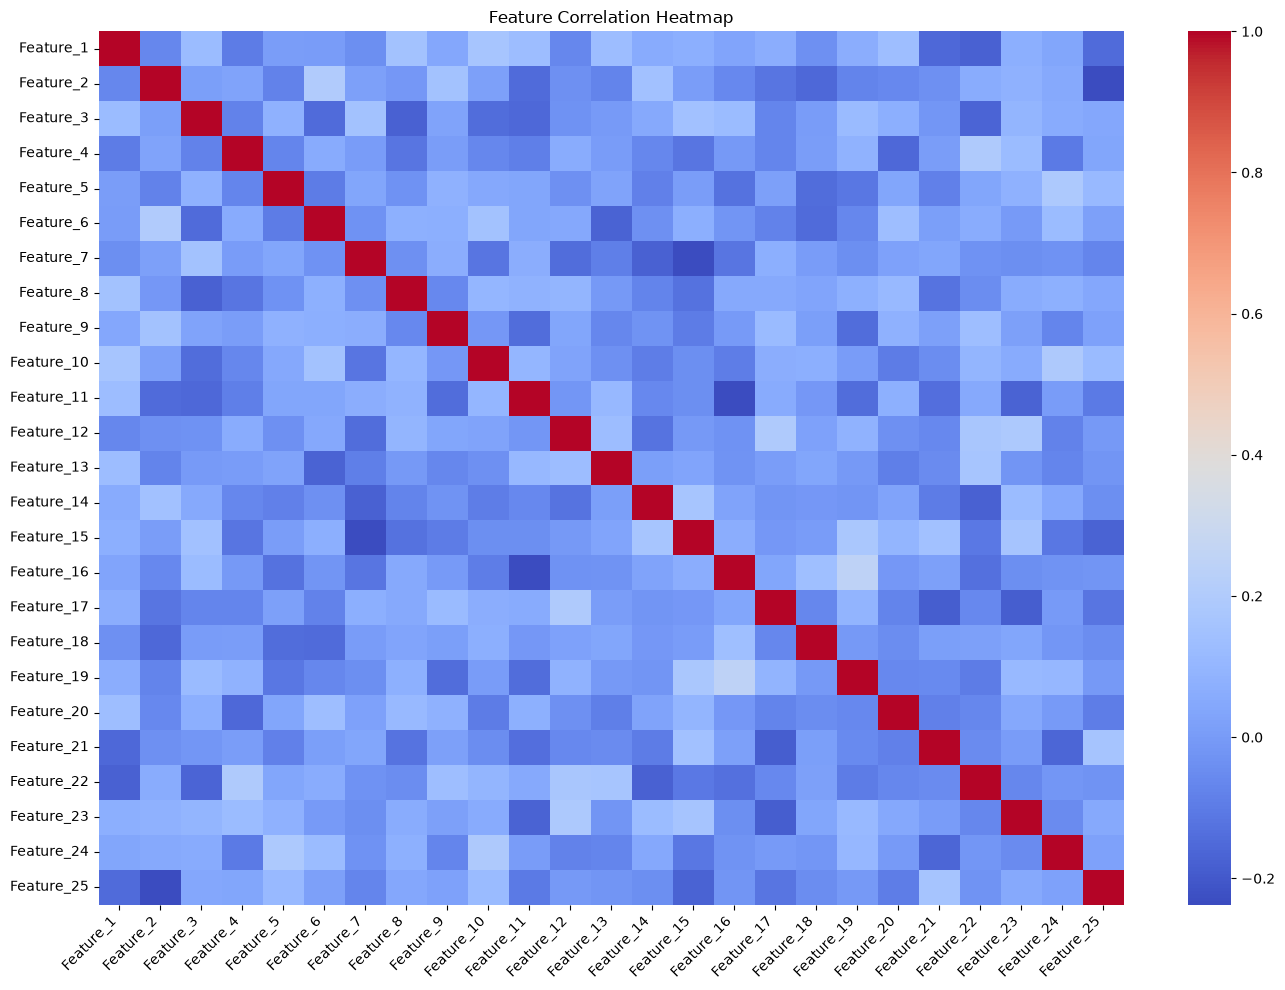

In [19]:

df = pd.DataFrame(
    np.random.rand(100, 25),
    columns=[f"Feature_{i}" for i in range(1, 26)]
)

corr = df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", annot=False)
plt.title("Feature Correlation Heatmap")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

<Axes: xlabel='Segment', ylabel='OrderValue'>

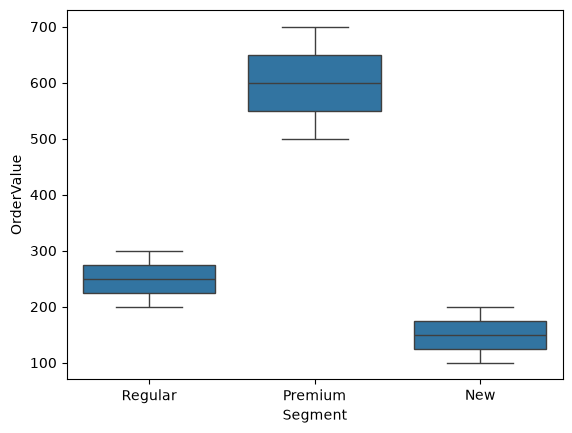

In [20]:
df = pd.DataFrame({
    "Segment": ["Regular", "Regular", "Regular",
                "Premium", "Premium", "Premium",
                "New", "New", "New"],
    "OrderValue": [200, 300, 250,
                   500, 700, 600,
                   100, 150, 200]
})

sns.boxplot(data=df, x="Segment", y="OrderValue")

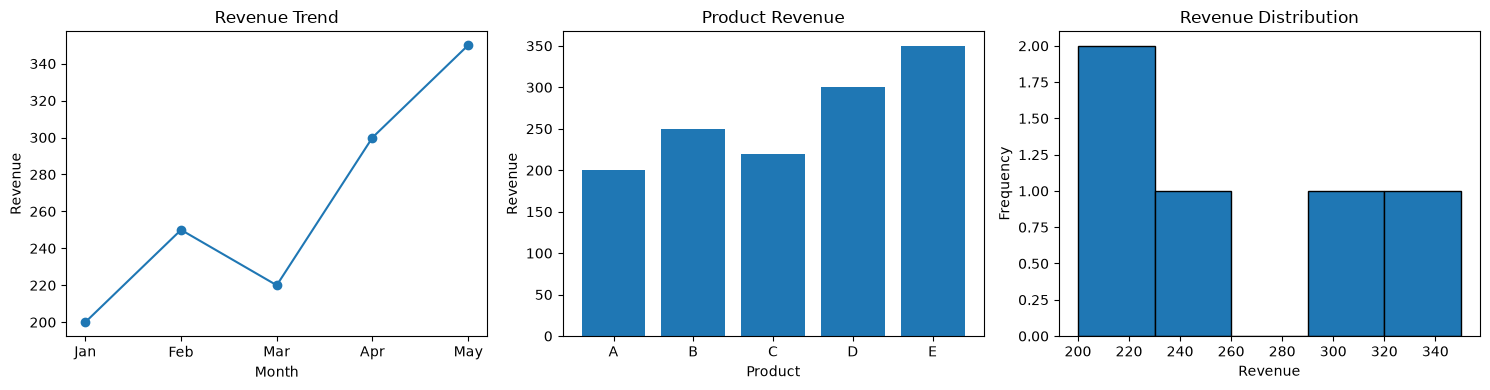

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May"],
    "Revenue": [200, 250, 220, 300, 350],
    "Product": ["A", "B", "C", "D", "E"]
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Revenue trend
axes[0].plot(df["Month"], df["Revenue"], marker="o")
axes[0].set_title("Revenue Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")

# 2. Product comparison
axes[1].bar(df["Product"], df["Revenue"])
axes[1].set_title("Product Revenue")
axes[1].set_xlabel("Product")
axes[1].set_ylabel("Revenue")

# 3. Revenue distribution
axes[2].hist(df["Revenue"], bins=5, edgecolor="black")
axes[2].set_title("Revenue Distribution")
axes[2].set_xlabel("Revenue")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Company-style answer guide

**Q1:** Use two lines on the same axes; add month labels, title, axis labels, markers, legend, and optionally grid.

**Q2:** Sort by `Revenue` descending, plot bars, label them, rotate crowded category labels, and call `tight_layout()`.

**Q3:** Use a histogram. `bins` controls the number or boundaries of intervals.

**Q4:** No. This shows association, not proof of causation. Other factors may influence sales.

**Q5:** Check the source record, units, data-entry mistakes, job level, and business context. Keep valid extreme values unless there is a justified reason to remove them.

**Q6:** Use `corr = df.corr(numeric_only=True)` and `sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)`. With 25 columns, labels can become crowded; increase figure size, select relevant columns, or use `annot=False`.

**Q7:** Use box plots to compare median, spread, and potential outliers; label the segments. Recent Matplotlib uses `tick_labels`; older versions may use `labels`.

**Q8:** Use a `2 × 2` subplot layout: line chart for revenue over time, bar chart for products, histogram for revenue distribution, and a scatter plot for two relevant numeric variables. Add titles and labels to each axis.

## Final checklist
- [ ] Create line, bar, pie, histogram, scatter, and box plots.
- [ ] Customize figure size, title, labels, legend, grid, ticks, limits, markers.
- [ ] Calculate and visualize correlations.
- [ ] Create subplots and pair plots.
- [ ] Choose a chart that matches a business question.
- [ ] Explain insights without unsupported causal claims.
- [ ] Complete the mini-project without copying every line.

**End of Matplotlib & Seaborn revision notebook — Lectures 59–66.**